# Tasks for laboratory assignment 3

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.preprocessing import PolynomialFeatures

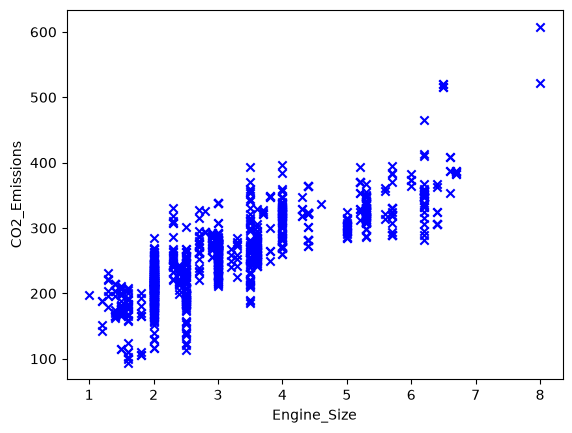

In [3]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [5]:
def extract_texts_from_file(file_path):
    """
    Extract the data from the csv file.

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        list: The list of records from the CSV file.
    """

    df = pd.read_csv(file_path)

    return df.to_dict(orient="records")


data = extract_texts_from_file("resources/heart.csv")
print(data[:5])

[{'age': 63, 'sex': 1, 'cp': 3, 'trtbps': 145, 'chol': 233, 'fbs': 1, 'restecg': 0, 'thalachh': 150, 'exng': 0, 'oldpeak': 2.3, 'slp': 0, 'caa': 0, 'thall': 1, 'output': 1}, {'age': 37, 'sex': 1, 'cp': 2, 'trtbps': 130, 'chol': 250, 'fbs': 0, 'restecg': 1, 'thalachh': 187, 'exng': 0, 'oldpeak': 3.5, 'slp': 0, 'caa': 0, 'thall': 2, 'output': 1}, {'age': 41, 'sex': 0, 'cp': 1, 'trtbps': 130, 'chol': 204, 'fbs': 0, 'restecg': 0, 'thalachh': 172, 'exng': 0, 'oldpeak': 1.4, 'slp': 2, 'caa': 0, 'thall': 2, 'output': 1}, {'age': 56, 'sex': 1, 'cp': 1, 'trtbps': 120, 'chol': 236, 'fbs': 0, 'restecg': 1, 'thalachh': 178, 'exng': 0, 'oldpeak': 0.8, 'slp': 2, 'caa': 0, 'thall': 2, 'output': 1}, {'age': 57, 'sex': 0, 'cp': 0, 'trtbps': 120, 'chol': 354, 'fbs': 0, 'restecg': 1, 'thalachh': 163, 'exng': 1, 'oldpeak': 0.6, 'slp': 2, 'caa': 0, 'thall': 2, 'output': 1}]


## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

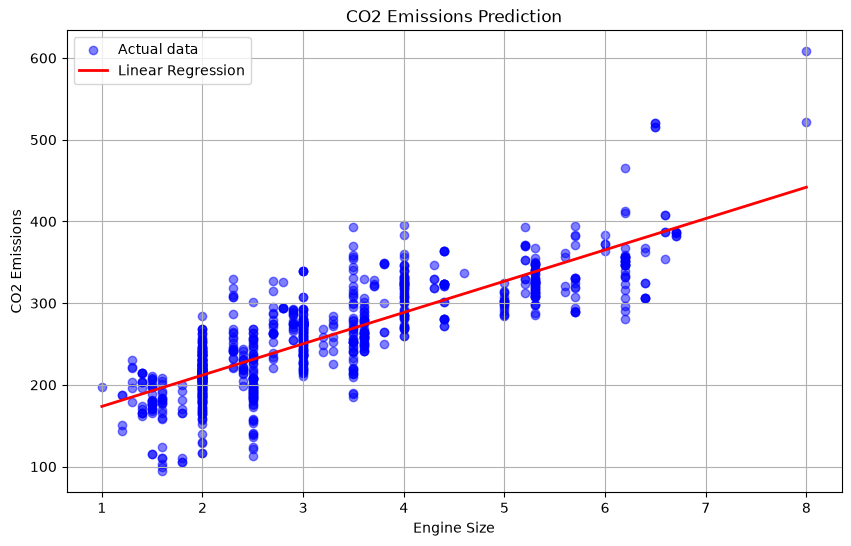

Model parameters: [135.3260546026322, 38.32301106042744]


[135.3260546026322, 38.32301106042744]

In [6]:
def CO2_emissions(data):
    """
    Build a model that predicts CO2 emissions
    based on engine size.

    Args:
        data: CO2 emissions data.

    Returns:
        list: Model theta parameters.
    """

    df = pd.DataFrame(data)

    # Input and target
    X = df[["Engine_Size"]]
    y = df["CO2_Emissions"]

    # Train model
    model = LinearRegression()
    model.fit(X, y)

    # Prepare regression line
    x_line = np.linspace(
        X["Engine_Size"].min(),
        X["Engine_Size"].max(),
        100
    )

    X_line = pd.DataFrame({"Engine_Size": x_line})
    y_line = model.predict(X_line)

    # Visualization
    plt.figure(figsize=(10, 6))

    plt.scatter(
        X["Engine_Size"],
        y,
        color="blue",
        alpha=0.5,
        label="Actual data"
    )

    plt.plot(
        x_line,
        y_line,
        color="red",
        linewidth=2,
        label="Linear Regression"
    )

    plt.xlabel("Engine Size")
    plt.ylabel("CO2 Emissions")
    plt.title("CO2 Emissions Prediction")
    plt.legend()
    plt.grid()

    plt.savefig("co2_emissions_regression.png")
    plt.show()

    # Model parameters
    theta = [
        float(model.intercept_),
        float(model.coef_[0])
    ]

    print("Model parameters:", theta)

    return theta


data = extract_texts_from_file("resources/CO2_emission.csv")
CO2_emissions(data)

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

Linear Regression R2: -0.5751
Polynomial Regression R2: 0.8431


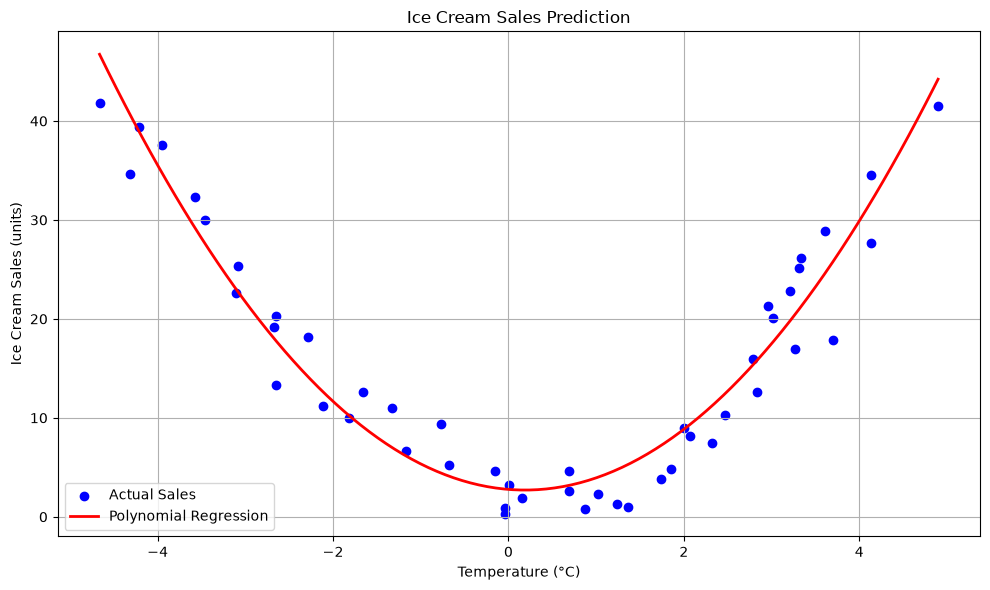

Best model: Polynomial Regression
Model parameters: [2.768305829573862, -0.7064192581346761, 1.8714512493550588]


[2.768305829573862, -0.7064192581346761, 1.8714512493550588]

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error


def ice_cream_selling(data):
    """
    Predict ice cream sales based on temperature.
    Compare linear and polynomial regression.

    Returns:
        list: Model theta parameters.
    """

    df = pd.DataFrame(data)

    X = df[["Temperature (°C)"]]
    y = df["Ice Cream Sales (units)"]

    # Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # 1. Linear Regression
    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)

    linear_pred = linear_model.predict(X_test)
    linear_r2 = r2_score(y_test, linear_pred)

    # 2. Polynomial Regression
    poly = PolynomialFeatures(degree=2, include_bias=False)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    poly_model = LinearRegression()
    poly_model.fit(X_train_poly, y_train)

    poly_pred = poly_model.predict(X_test_poly)
    poly_r2 = r2_score(y_test, poly_pred)

    print("Linear Regression R2:", round(linear_r2, 4))
    print("Polynomial Regression R2:", round(poly_r2, 4))

    # Prepare prediction line
    x_line = np.linspace(
        X.iloc[:, 0].min(),
        X.iloc[:, 0].max(),
        200
    )

    X_line = pd.DataFrame({"Temperature (°C)": x_line})

    # Choose the better model
    if poly_r2 > linear_r2:
        y_line = poly_model.predict(poly.transform(X_line))
        theta = [float(poly_model.intercept_)] + poly_model.coef_.tolist()
        model_name = "Polynomial Regression"
    else:
        y_line = linear_model.predict(X_line)
        theta = [float(linear_model.intercept_)] + linear_model.coef_.tolist()
        model_name = "Linear Regression"

    # Visualization
    plt.figure(figsize=(10, 6))

    plt.scatter(
        X["Temperature (°C)"],
        y,
        color="blue",
        label="Actual Sales"
    )

    plt.plot(
        x_line,
        y_line,
        color="red",
        linewidth=2,
        label=model_name
    )

    plt.xlabel("Temperature (°C)")
    plt.ylabel("Ice Cream Sales (units)")
    plt.title("Ice Cream Sales Prediction")
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.savefig("ice_cream_regression.png")
    plt.show()
    plt.close()

    print("Best model:", model_name)
    print("Model parameters:", theta)

    return theta


data = extract_texts_from_file("resources/ice_cream_selling_data.csv")
ice_cream_selling(data)

## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

Linear Regression R2: 0.0526
Polynomial Regression R2: 0.0484
Best model: Linear Regression
MAE: 5091.73
R2: 0.0526


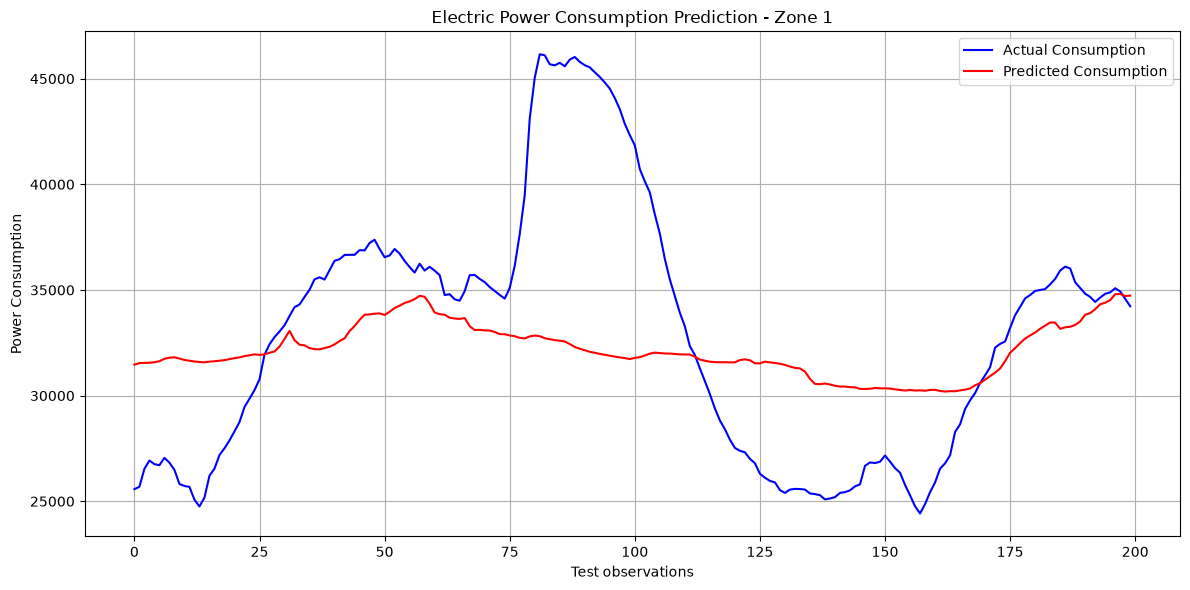

Model parameters: [27068.256667276295, 488.49923592042927, -45.87682985522623, -213.48154508160857]


[27068.256667276295,
 488.49923592042927,
 -45.87682985522623,
 -213.48154508160857]

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error


def power_consumption(data):
    """
    Predict electricity consumption using
    temperature, humidity and wind speed.

    Returns:
        list: Model theta parameters.
    """

    df = pd.DataFrame(data)

    # Select features and target
    features = ["Temperature", "Humidity", "WindSpeed"]
    target = "PowerConsumption_Zone1"

    df = df.dropna(subset=features + [target])

    X = df[features]
    y = df[target]

    # Split data chronologically: 80% training, 20% testing
    split = int(len(df) * 0.8)

    X_train = X.iloc[:split]
    X_test = X.iloc[split:]

    y_train = y.iloc[:split]
    y_test = y.iloc[split:]

    # 1. Linear Regression
    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)

    linear_pred = linear_model.predict(X_test)
    linear_r2 = r2_score(y_test, linear_pred)

    # 2. Polynomial Regression
    poly = PolynomialFeatures(degree=2, include_bias=False)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    poly_model = LinearRegression()
    poly_model.fit(X_train_poly, y_train)

    poly_pred = poly_model.predict(X_test_poly)
    poly_r2 = r2_score(y_test, poly_pred)

    # Compare models
    print("Linear Regression R2:", round(linear_r2, 4))
    print("Polynomial Regression R2:", round(poly_r2, 4))

    # Choose best model
    if poly_r2 > linear_r2:
        predictions = poly_pred
        model = poly_model
        model_name = "Polynomial Regression"
    else:
        predictions = linear_pred
        model = linear_model
        model_name = "Linear Regression"

    # Model evaluation
    print("Best model:", model_name)
    print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
    print("R2:", round(r2_score(y_test, predictions), 4))

    # Visualization
    plt.figure(figsize=(12, 6))

    plt.plot(
        y_test.iloc[:200].values,
        label="Actual Consumption",
        color="blue"
    )

    plt.plot(
        predictions[:200],
        label="Predicted Consumption",
        color="red"
    )

    plt.xlabel("Test observations")
    plt.ylabel("Power Consumption")
    plt.title("Electric Power Consumption Prediction - Zone 1")
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.savefig("power_consumption_regression.png")
    plt.show()
    plt.close()

    # Model parameters
    theta = [float(model.intercept_)] + model.coef_.tolist()

    print("Model parameters:", theta)

    return theta


data = extract_texts_from_file("resources/powerconsumption.csv")
power_consumption(data)

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

Training samples: 242
Validation samples: 61
Accuracy: 0.8033

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.68      0.76        28
           1       0.77      0.91      0.83        33

    accuracy                           0.80        61
   macro avg       0.82      0.79      0.80        61
weighted avg       0.81      0.80      0.80        61



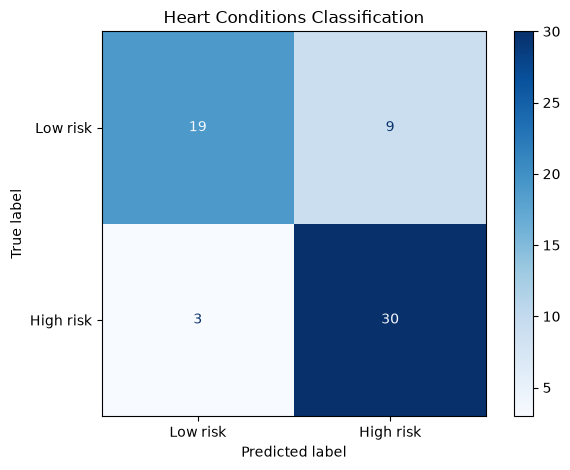

Model parameters: [0.13159523820583108, 0.017735892695205903, -0.714030156797815, 0.9377354404244739, -0.2114365918793342, -0.45921005774159007, -0.0636488598350697, 0.2354714500702065, 0.5396293104526307, -0.47588301638238667, -0.5948186666294084, 0.30786705297888317, -0.5592027955256132, -0.6215780683618345]


[0.13159523820583108,
 0.017735892695205903,
 -0.714030156797815,
 0.9377354404244739,
 -0.2114365918793342,
 -0.45921005774159007,
 -0.0636488598350697,
 0.2354714500702065,
 0.5396293104526307,
 -0.47588301638238667,
 -0.5948186666294084,
 0.30786705297888317,
 -0.5592027955256132,
 -0.6215780683618345]

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


def heart_classification(data):
    """
    Build a classification model for heart conditions.
    Visualize and validate the model.

    Args:
        data: Heart medical data.

    Returns:
        list: Model theta parameters.
    """

    df = pd.DataFrame(data)

    # 1. Select features and target
    X = df.drop(columns=["output"])
    y = df["output"]

    # 2. Split data into training and validation sets
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # 3. Create and train the model
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )

    model.fit(X_train, y_train)

    # 4. Make predictions
    predictions = model.predict(X_test)

    # 5. Evaluate model
    accuracy = accuracy_score(y_test, predictions)

    print("Training samples:", len(X_train))
    print("Validation samples:", len(X_test))
    print("Accuracy:", round(accuracy, 4))

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))

    # 6. Confusion Matrix
    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Low risk", "High risk"]
    )

    disp.plot(cmap="Blues")

    plt.title("Heart Conditions Classification")
    plt.tight_layout()
    plt.savefig("heart_classification.png")
    plt.show()
    plt.close()

    # 7. Model parameters
    classifier = model.named_steps["logisticregression"]

    theta = [
        float(classifier.intercept_[0])
    ] + classifier.coef_[0].tolist()

    print("Model parameters:", theta)

    return theta


data = extract_texts_from_file("resources/heart.csv")
heart_classification(data)

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

Model: Linear Regression
Training samples: 5447
Test samples: 1362
R2: 0.9609
MAE: 1.2229


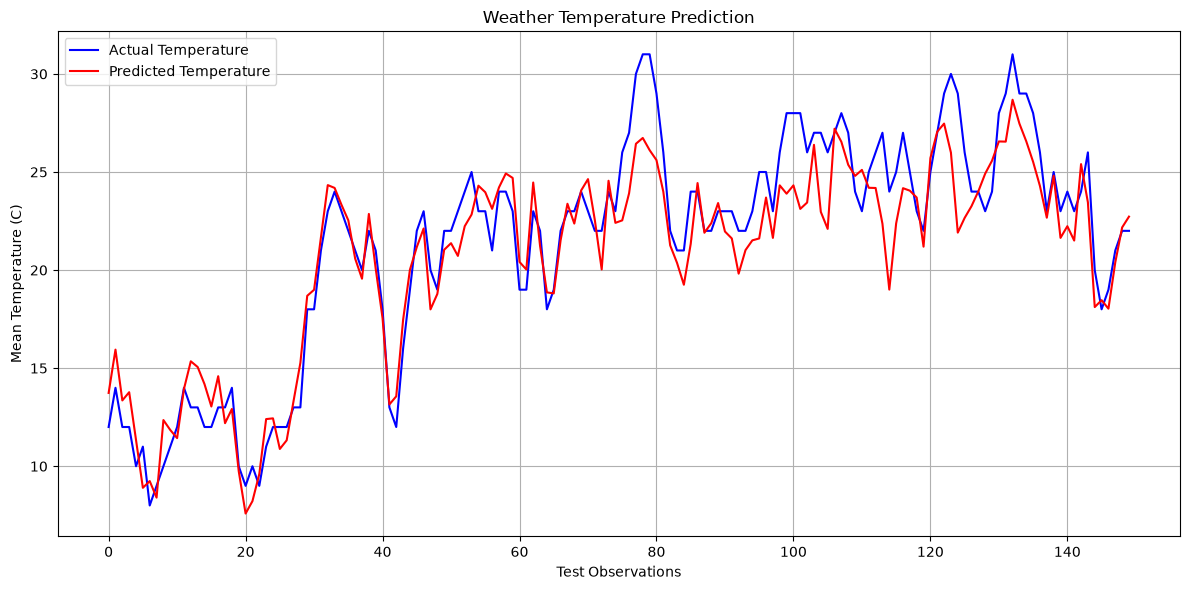

Model parameters: [27.33860750371536, 1.0460906214000525, -0.29744302388097493, -0.06335914244775102, 0.0]


[27.33860750371536,
 1.0460906214000525,
 -0.29744302388097493,
 -0.06335914244775102,
 0.0]

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error


def additional(data):
    """
    Predict mean temperature using weather data.
    Train and evaluate a regression model.
    Visualize actual and predicted temperatures.

    Returns:
        list: Model theta parameters.
    """

    df = pd.DataFrame(data)

    # Remove extra spaces from column names
    df.columns = df.columns.str.strip()

    # Select features and target
    features = [
        "MeanDew PointC",
        "Mean Humidity",
        "Mean Wind SpeedKm/h",
        "Precipitationmm"
    ]

    target = "Mean TemperatureC"

    # Convert columns to numeric values
    for column in features + [target]:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    # Remove rows without target values
    df = df.dropna(subset=[target])

    X = df[features]
    y = df[target]

    # Split data chronologically: 80% training, 20% testing
    split = int(len(df) * 0.8)

    X_train = X.iloc[:split]
    X_test = X.iloc[split:]

    y_train = y.iloc[:split]
    y_test = y.iloc[split:]

    # Train model
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    # Make predictions
    predictions = model.predict(X_test)

    # Evaluate model
    r2 = r2_score(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)

    print("Model: Linear Regression")
    print("Training samples:", len(X_train))
    print("Test samples:", len(X_test))
    print("R2:", round(r2, 4))
    print("MAE:", round(mae, 4))

    # Visualize results
    plt.figure(figsize=(12, 6))

    plt.plot(
        y_test.iloc[:150].values,
        label="Actual Temperature",
        color="blue"
    )

    plt.plot(
        predictions[:150],
        label="Predicted Temperature",
        color="red"
    )

    plt.xlabel("Test Observations")
    plt.ylabel("Mean Temperature (C)")
    plt.title("Weather Temperature Prediction")
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.savefig("weather_temperature_prediction.png")
    plt.show()
    plt.close()

    # Model parameters
    regression = model.named_steps["linearregression"]

    theta = [
        float(regression.intercept_)
    ] + regression.coef_.tolist()

    print("Model parameters:", theta)

    return theta


data = extract_texts_from_file("resources/weather.csv")
additional(data)

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.). 

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv



Dataset shape: (107018, 3)
Columns: ['Id', 'Review', 'Label']
Total reviews: 107018

Rating distribution:
Label
1     2469
2     2251
3     5071
4    18054
5    79173
Name: count, dtype: int64

Model: SGDClassifier
Training samples: 85614
Validation samples: 21404
Accuracy: 0.7623
Macro F1-score: 0.2379

Classification Report:
              precision    recall  f1-score   support

           1       0.56      0.01      0.02       494
           2       0.00      0.00      0.00       450
           3       0.42      0.02      0.04      1014
           4       0.45      0.18      0.26      3611
           5       0.79      0.99      0.88     15835

    accuracy                           0.76     21404
   macro avg       0.44      0.24      0.24     21404
weighted avg       0.69      0.76      0.69     21404



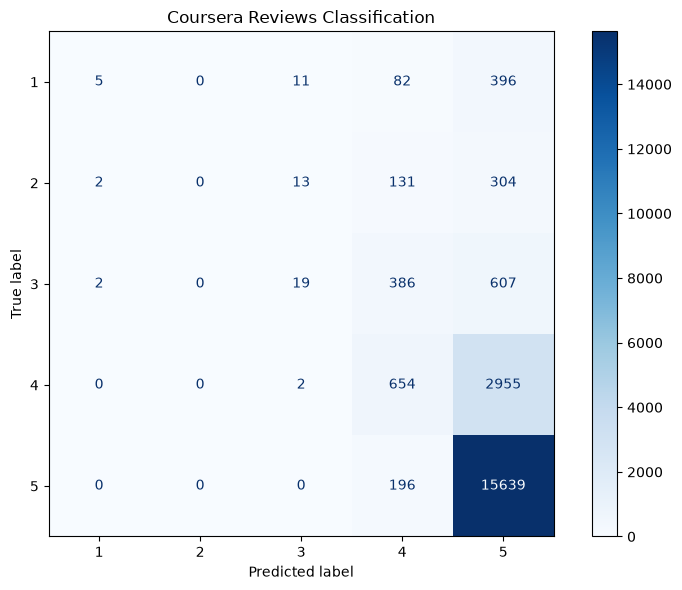

In [32]:

import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)


# 1. Load dataset from Kaggle
def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle and fix encoding issues.

    Returns:
        pd.DataFrame: Loaded dataset.
    """

    path = kagglehub.dataset_download(url)
    file_path = Path(path) / csv_file

    df = pd.read_csv(
        file_path,
        encoding="utf-8",
        encoding_errors="replace"
    )

    return df


# 2. Classify text using machine learning
def classify_text_ml(df):
    """
    Classify Coursera reviews by rating (1-5).

    Args:
        df (pd.DataFrame): Dataset with Review and Label columns.

    Returns:
        None
    """

    df = df.copy()

    # Clean data
    df["Label"] = pd.to_numeric(
        df["Label"], errors="coerce"
    )

    df = df.dropna(subset=["Review", "Label"])
    df = df[df["Review"].astype(str).str.strip() != ""]

    X = df["Review"].astype(str)
    y = df["Label"].astype(int)

    print("Total reviews:", len(df))
    print("\nRating distribution:")
    print(y.value_counts().sort_index())

    # Split into training and validation data
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # TF-IDF vectorization
    vectorizer = TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=3,
        sublinear_tf=True
    )

    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    # Train classification model
    model = SGDClassifier(
        loss="log_loss",
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_tfidf, y_train)

    # Make predictions
    predictions = model.predict(X_test_tfidf)

    # Evaluate model
    accuracy = accuracy_score(y_test, predictions)

    f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    print("\nModel: SGDClassifier")
    print("Training samples:", len(X_train))
    print("Validation samples:", len(X_test))
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1-score:", round(f1, 4))

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )

    # Confusion Matrix
    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        cmap="Blues",
        ax=ax,
        values_format="d"
    )

    plt.title("Coursera Reviews Classification")
    plt.tight_layout()

    plt.savefig("coursera_reviews_confusion_matrix.png")
    plt.show()
    plt.close()


# 3. Download and analyze dataset
df = load_dataset(
    "septa97/100k-courseras-course-reviews-dataset",
    "reviews.csv"
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

classify_text_ml(df)
